In [25]:
import os, random, math, time, itertools
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from torchvision.models import resnet50, ResNet50_Weights
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import torch.onnx
from torch.export import Dim
import onnxruntime as ort

In [2]:
#Задаём сиды для повторяемости экспериментов
def seed_everything(seed: int = 69):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(69)

In [3]:
print("Версия PyTorch:", torch.__version__)
print("CUDA доступна:", torch.cuda.is_available())
print("Имя GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Не найдена")

Версия PyTorch: 2.11.0+cu128
CUDA доступна: True
Имя GPU: NVIDIA GeForce RTX 3060


In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [5]:
root = './data'

In [6]:
# Статистики для нормализации данных
raw = datasets.MNIST(root=root, train=True, download=True)
x = raw.data.float() / 255.0

mnist_mean = (x.mean().item(),)
mnist_std = (x.std().item(),)

print('MNIST mean:', mnist_mean)
print('MNIST std:', mnist_std)

MNIST mean: (0.13066047430038452,)
MNIST std: (0.30810782313346863,)


In [7]:
# Нормализация
train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mnist_mean, mnist_std),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mnist_mean, mnist_std),
])

In [8]:
full_train = datasets.MNIST(root=root, train=True, download=True, transform=train_transform)
mnist_test = datasets.MNIST(root=root, train=False, download=True, transform=test_transform)

len(full_train), len(mnist_test)

(60000, 10000)

In [9]:
# Разбиение на выборки
val_ratio = 0.1
val_size = int(len(full_train) * val_ratio)
train_size = len(full_train) - val_size
mnist_train, mnist_val = random_split(full_train, [train_size, val_size])
len(mnist_train), len(mnist_val), len(mnist_test)

(54000, 6000, 10000)

In [10]:
# Модель
class MyCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2), # 28x28 -> 14x14

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2), # 14x14 -> 7x7
            nn.Dropout(0.25),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)), # 7x7 -> 1x1
            nn.Dropout(0.5)
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.head(x)
        return x

model_mnist = MyCNN().to(device)

In [11]:
def accuracy(logits, y):
    preds = logits.argmax(dim=1)
    return (preds == y).float().mean().item()

In [12]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()


    total_loss, total_acc, total_count = 0.0, 0.0, 0


    for x, y in tqdm(loader, leave=False):
        x, y = x.to(device), y.to(device)
        if is_train:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(is_train):
            logits = model(x)
            loss = criterion(logits, y)
            if is_train:
                loss.backward()
                optimizer.step()
        bs = x.size(0)
        total_loss += loss.item() * bs
        total_acc += accuracy(logits, y) * bs
        total_count += bs

    return total_loss/total_count, total_acc/total_count

In [13]:
# Параметры обучения и загрузчики
batch_size = 128

train_loader = DataLoader(mnist_train, batch_size=batch_size, shuffle=True, pin_memory=True)
val_loader = DataLoader(mnist_val, batch_size=batch_size, shuffle=False, pin_memory=True)
test_loader = DataLoader(mnist_test, batch_size=batch_size, shuffle=False, pin_memory=True)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_mnist.parameters(), lr=1e-3)

In [14]:
num_epochs = 20
hist = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}

In [15]:
for epoch in range(1, num_epochs+1):
    tr_loss, tr_acc = run_epoch(model_mnist, train_loader, criterion, optimizer)
    va_loss, va_acc = run_epoch(model_mnist, val_loader, criterion, optimizer=None)


    hist['train_loss'].append(tr_loss)
    hist['train_acc'].append(tr_acc)
    hist['val_loss'].append(va_loss)
    hist['val_acc'].append(va_acc)


    print(f"Epoch {epoch:02d} | Train: loss={tr_loss:.4f}, acc={tr_acc:.4f} | Val: loss={va_loss:.4f}, acc={va_acc:.4f}")

  0%|          | 0/422 [00:00<?, ?it/s]

  0%|          | 0/47 [00:00<?, ?it/s]

Epoch 01 | Train: loss=0.7762, acc=0.7372 | Val: loss=0.2122, acc=0.9343


  0%|          | 0/422 [00:00<?, ?it/s]

  0%|          | 0/47 [00:00<?, ?it/s]

Epoch 02 | Train: loss=0.2681, acc=0.9201 | Val: loss=0.1089, acc=0.9665


... (50 outputs left out)

Epoch 19 | Train: loss=0.0547, acc=0.9832 | Val: loss=0.0330, acc=0.9898


  0%|          | 0/422 [00:00<?, ?it/s]

  0%|          | 0/47 [00:00<?, ?it/s]

Epoch 20 | Train: loss=0.0498, acc=0.9842 | Val: loss=0.0285, acc=0.9920


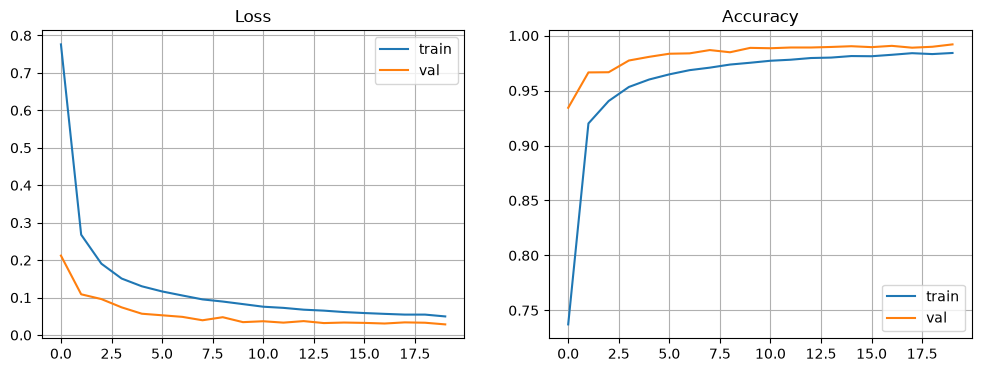

In [16]:
# Графики обучения
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(hist['train_loss'], label='train')
plt.plot(hist['val_loss'], label='val')
plt.title('Loss')
plt.legend()
plt.grid(True)


plt.subplot(1,2,2)
plt.plot(hist['train_acc'], label='train')
plt.plot(hist['val_acc'], label='val')
plt.title('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

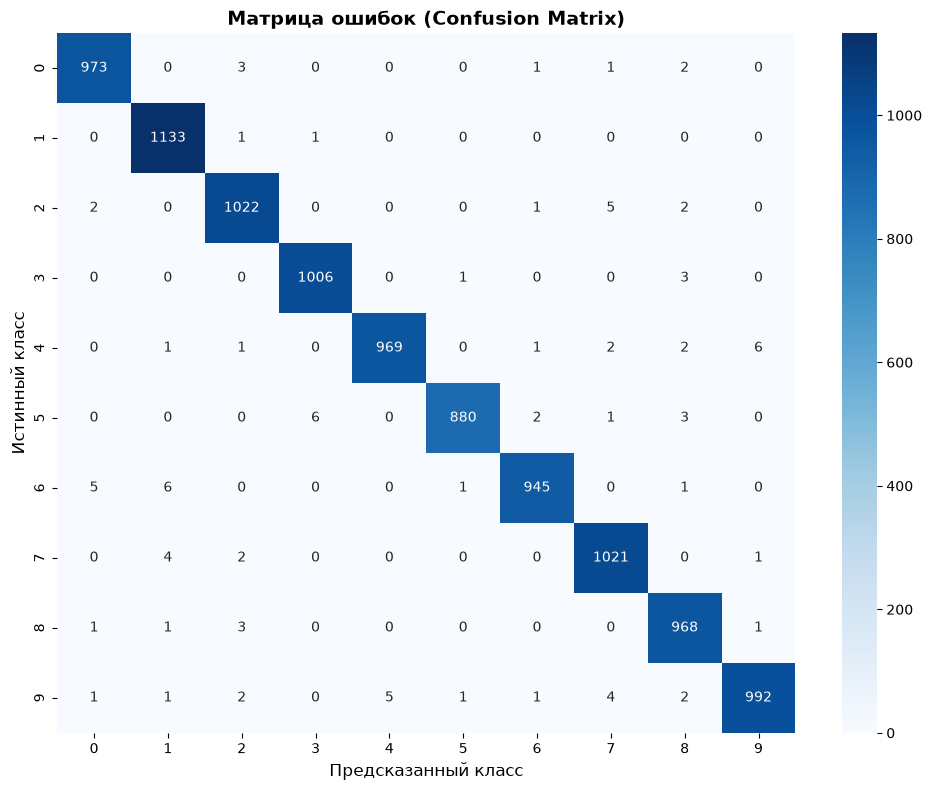

              precision    recall  f1-score   support

           0     0.9908    0.9929    0.9918       980
           1     0.9887    0.9982    0.9934      1135
           2     0.9884    0.9903    0.9894      1032
           3     0.9931    0.9960    0.9946      1010
           4     0.9949    0.9868    0.9908       982
           5     0.9966    0.9865    0.9915       892
           6     0.9937    0.9864    0.9900       958
           7     0.9874    0.9932    0.9903      1028
           8     0.9847    0.9938    0.9893       974
           9     0.9920    0.9832    0.9876      1009

    accuracy                         0.9909     10000
   macro avg     0.9910    0.9907    0.9909     10000
weighted avg     0.9909    0.9909    0.9909     10000



In [17]:
# Оценка результатов
def collect_preds(model, loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            logits = model(xb)
            preds = logits.argmax(dim=1).cpu()
            y_true.append(yb)
            y_pred.append(preds)
    y_true = torch.cat(y_true).numpy()
    y_pred = torch.cat(y_pred).numpy()
    return y_true, y_pred

def plot_confusion_matrix(model, loader):
    y_true, y_pred = collect_preds(model, loader)
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(10), yticklabels=range(10))
    plt.xlabel('Предсказанный класс', fontsize=12)
    plt.ylabel('Истинный класс', fontsize=12)
    plt.title('Матрица ошибок (Confusion Matrix)', fontsize=14, weight='bold')
    plt.tight_layout()
    plt.show()

    print(classification_report(y_true, y_pred, digits=4))
    return cm

cm = plot_confusion_matrix(model_mnist, test_loader)

In [30]:
model_mnist.eval() 
dummy_input = torch.randn(1, 1, 28, 28, device=device)
onnx_model_path = r"D:\учёба\Магистратура\нейронки\mnist_cnn4.onnx"
batch_dim = Dim("batch_size", min=1, max=128)

torch.onnx.export(
    model_mnist,
    dummy_input,
    onnx_model_path,
    export_params=True,
    opset_version=18, 
    do_constant_folding=True,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes={
        'input': {0: batch_dim},
        'output': {0: batch_dim}
    },
)

C:\Users\SDA\AppData\Local\Temp\ipykernel_13404\3723975378.py:6: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(


[torch.onnx] Obtain model graph for `MyCNN([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MyCNN([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


C:\Users\SDA\AppData\Local\Python\pythoncore-3.14-64\Lib\copyreg.py:104: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


ONNXProgram(
    model=
        <
            ir_version=10,
            opset_imports={'': 18},
            producer_name='pytorch',
            producer_version='2.11.0+cu128',
            domain=None,
            model_version=None,
        >
        graph(
            name=main_graph,
            inputs=(
                %"input"<FLOAT,[batch_size,1,28,28]>
            ),
            outputs=(
                %"output"<FLOAT,[batch_size,10]>
            ),
            initializers=(
                %"features.0.weight"<FLOAT,[32,1,3,3]>{Tensor(...)},
                %"features.0.bias"<FLOAT,[32]>{Tensor(...)},
                %"features.4.weight"<FLOAT,[64,32,3,3]>{Tensor(...)},
                %"features.4.bias"<FLOAT,[64]>{Tensor(...)},
                %"features.9.weight"<FLOAT,[128,64,3,3]>{Tensor(...)},
                %"features.9.bias"<FLOAT,[128]>{Tensor(...)},
                %"head.1.weight"<FLOAT,[256,128]>{TorchTensor(...)},
                %"head.1.bias"<FLOAT,[256]>{T

In [31]:
providers = ['CPUExecutionProvider']
ort_session = ort.InferenceSession(onnx_model_path, providers=providers)

print("Доступные провайдеры:", ort.get_available_providers())
print("Входные данные модели:", ort_session.get_inputs()[0].name, ort_session.get_inputs()[0].shape)
print("Выходные данные модели:", ort_session.get_outputs()[0].name, ort_session.get_outputs()[0].shape)

images, labels = next(iter(test_loader))
single_image = images[0].unsqueeze(0).cpu().numpy()
true_label = labels[0].item()
inputs = {ort_session.get_inputs()[0].name: single_image}
outputs = ort_session.run(None, inputs)
logits = outputs[0]
predicted_class = np.argmax(logits, axis=1)[0]
print(f"\nИстинная цифра: {true_label}")
print(f"Предсказанная цифра (ONNX): {predicted_class}")
print(f"Уверенность модели: {torch.softmax(torch.tensor(logits), dim=1)[0][predicted_class].item():.4f}")

Доступные провайдеры: ['AzureExecutionProvider', 'CPUExecutionProvider']
Входные данные модели: input ['batch_size', 1, 28, 28]
Выходные данные модели: output ['batch_size', 10]

Истинная цифра: 7
Предсказанная цифра (ONNX): 7
Уверенность модели: 1.0000


In [34]:
# Предсказания PyTorch модели
model_mnist.eval()
with torch.no_grad():
    pytorch_logits = model_mnist(images.to(device)).cpu().numpy()
pytorch_preds = np.argmax(pytorch_logits, axis=1)

# Предсказания ONNX модели для всего батча
# размерность images (128, 1, 28, 28)
onnx_inputs = {ort_session.get_inputs()[0].name: images.cpu().numpy()}
onnx_logits = ort_session.run(None, onnx_inputs)[0]
onnx_preds = np.argmax(onnx_logits, axis=1)

# Сравние
matches = np.sum(pytorch_preds == onnx_preds)
total = len(pytorch_preds)
max_diff = np.max(np.abs(pytorch_logits - onnx_logits))

print(f"Совпадение предсказаний: {matches} из {total} ({matches/total*100:.2f}%)")
print(f"Максимальное расхождение в логитах: {max_diff:.6f}")

if matches == total:
    print("Модели работают идентично!")
else:
    print("Есть расхождения в предсказаниях.")

Совпадение предсказаний: 128 из 128 (100.00%)
Максимальное расхождение в логитах: 0.004818
Модели работают идентично!
